# 02 · Price analysis: what is a fair price on Tiki?

**Business question:** a shopper (or a seller setting a price) wants to know, for one type of product, *what price is normal*, *below which price a listing looks suspicious*, and *which price range actually sells*.

**Data:** `data/sample/tiki_sample.csv`, built in `01_data_collection.ipynb` — products listed on Tiki for three keywords from different product types, collected at the same moment.

**Questions**

1. Is the data good enough to analyse?
2. What does the price distribution look like, and which prices are unusual?
3. What are the reference prices (floor, common range, median)?
4. Which price segment sells — and how concentrated are sales?
5. What is related to sales: price, rating, discount, reviews?
6. Does the deal score pick sensible products?

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter, PercentFormatter

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from analysis.pricing import price_band, price_fences

FIGURES = ROOT / "docs" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

# Chart style: thin marks, hairline grid, one colour per keyword (fixed order)
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
GRAY, INK, INK2, GRID = "#c3c2b7", "#0b0b0b", "#52514e", "#e1e0d9"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GRAY,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False,
})
# 250000 -> "250K", 1500000 -> "1.5M"
vnd_short = FuncFormatter(lambda x, _: f"{x / 1e6:g}M" if x >= 1e6 else f"{x / 1e3:g}K")
pd.set_option("display.max_colwidth", 55)

## 1. Is the data good enough to analyse?

In [2]:
df = pd.read_csv(ROOT / "data" / "sample" / "tiki_sample.csv")
KEYWORDS = list(df["keyword"].unique())
COLORS = dict(zip(KEYWORDS, [BLUE, ORANGE, AQUA]))

print(df.shape)
print("Collected at:", df["crawled_at"].iloc[0])
df.groupby("keyword").agg(products=("product_id", "size"), categories=("category", "nunique"))

(567, 18)
Collected at: 2026-10-24 10:27


,products,categories
keyword,,
chuột gaming,173,5
nồi chiên không dầu,197,4
tai nghe bluetooth,197,19


In [3]:
# Data quality checks: every line should print True
checks = {
    "no duplicated product per keyword": not df.duplicated(["keyword", "source", "product_id"]).any(),
    "every price > 0":                   (df["price"] > 0).all(),
    "original price >= price":           (df["original_price"] >= df["price"]).all(),
    "discount between 0 and 100 %":      df["discount_pct"].between(0, 100).all(),
    "rating empty or between 1 and 5":   df["rating"].dropna().between(1, 5).all(),
    "sold and reviews never negative":   (df[["sold", "review_count"]] >= 0).all().all(),
    "every product has a link":          df["product_url"].notna().all(),
}
for name, ok in checks.items():
    print(f"{ok!s:>5}  {name}")

 True  no duplicated product per keyword
 True  every price > 0
 True  original price >= price
 True  discount between 0 and 100 %
 True  rating empty or between 1 and 5
 True  sold and reviews never negative
 True  every product has a link


In [4]:
# Missing values: only brand and rating may be empty, and both are expected
(df.isna().mean() * 100).round(1).loc[lambda s: s > 0].to_frame("missing %")

,missing %
brand,3.0
rating,69.0
deal_score,3.4


Brand is empty for "OEM / No Brand" products, and rating is empty for products **nobody has rated yet** — after cleaning, empty does not mean zero.

### Analyse one category at a time

A search for "chuột gaming" also returns mouse pads; "tai nghe bluetooth" returns several kinds of headphones. Mixing them would distort every price statistic, so each keyword is analysed on its **main category** (the most common one).

In [5]:
main_category = df.groupby("keyword")["category"].agg(lambda s: s.value_counts().idxmax())
share = df.groupby("keyword")["category"].agg(lambda s: s.value_counts(normalize=True).iloc[0] * 100)
pd.DataFrame({"main category": main_category, "share of results %": share.round(1)})

,main category,share of results %
keyword,,
chuột gaming,Chuột Chơi Game,87.9
nồi chiên không dầu,Nồi chiên,95.4
tai nghe bluetooth,Tai Nghe True Wireless,36.0


In [6]:
main = df[df["category"] == df["keyword"].map(main_category)].copy()
normal = main[main["price_flag"] == "normal"]
main.groupby("keyword").size().to_frame("products in the main category")

,products in the main category
keyword,
chuột gaming,152
nồi chiên không dầu,188
tai nghe bluetooth,71


## 2. Price distribution and unusual prices

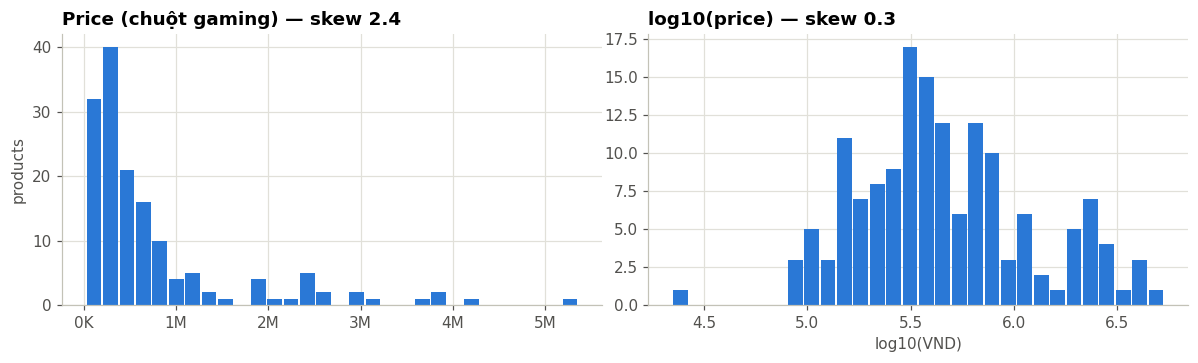

In [7]:
prices = main.loc[main["keyword"] == KEYWORDS[0], "price"]

fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.4))
left.hist(prices, bins=30, color=BLUE, rwidth=0.9)
left.set_title(f"Price ({KEYWORDS[0]}) — skew {prices.skew():.1f}")
left.xaxis.set_major_formatter(vnd_short)
left.set_ylabel("products")

right.hist(np.log10(prices), bins=30, color=BLUE, rwidth=0.9)
right.set_title(f"log10(price) — skew {np.log10(prices).skew():.1f}")
right.set_xlabel("log10(VND)")
plt.tight_layout()

Prices are strongly **right-skewed**: most products are cheap, a few are very expensive. On a log scale the shape is close to symmetric, so the IQR rule for unusual prices is applied to `log10(price)` (on raw prices the lower fence would be negative and could never catch a suspiciously cheap listing).

In [8]:
rows = []
for keyword, group in main.groupby("keyword", sort=False):
    low, high = price_fences(group["price"])
    rows.append({"keyword": keyword, "low fence": int(round(low, -3)), "high fence": int(round(high, -3)),
                 "unusual products": int((group["price_flag"] != "normal").sum())})
pd.DataFrame(rows).set_index("keyword")

,low fence,high fence,unusual products
keyword,,,
chuột gaming,40000,4768000,2
tai nghe bluetooth,148000,5492000,4
nồi chiên không dầu,649000,12879000,1


In [9]:
main.loc[main["price_flag"] != "normal", ["keyword", "name", "price", "price_flag"]].sort_values(["keyword", "price"])

,keyword,name,price,price_flag
71,chuột gaming,Chuột Game Chuyên Dụng Đèn Led - Màu ngẫu nhiên,22093,low
120,chuột gaming,Chuột không dây Gaming Logitech Pro X2 Superstrike ...,5359000,high
397,nồi chiên không dầu,"Nồi Chiên Không Dầu 8L , Nướng Gà Cả Con - Bếp Nướ...",599000,low
301,tai nghe bluetooth,Tai nghe Bluetooth True Wireless Xiaomi FlipBuds Pr...,5990000,high
345,tai nghe bluetooth,Tai nghe Bluetooth True Wireless JBL Live Beam 4 - ...,6290000,high
348,tai nghe bluetooth,Tai nghe Bluetooth Apple AirPods Pro 3 - MFHP4ZP/A,6290000,high
367,tai nghe bluetooth,Tai nghe Bluetooth True Wireless Sony WF-1000XM6 - ...,9564000,high


Only **7 of 411** products in the main categories are flagged, and they are of two kinds:

- **too expensive** — flagship products (AirPods Pro 3, Sony WF-1000XM6, Logitech Pro X2) that are real but belong to a different market tier;
- **too cheap** — a 22 000 ₫ "gaming mouse" (almost certainly a different product or a mistake) and a 599 000 ₫ 8-litre air fryer, cheaper than every other air fryer in the results.

A flag is not proof that a listing is fake; it means *check before trusting this price*. Flagged products are excluded from the reference prices below.

## 3. Reference prices

Computed on normal prices only (see `analysis/pricing.py`):

- **floor** — 10th percentile: 90 % of listings cost more. A much cheaper listing deserves a closer look.
- **Q1–Q3** — the common price range (middle 50 % of listings).
- **sales-weighted median** — the median price *of units sold*, i.e. what buyers actually pay.

In [10]:
bands = pd.DataFrame({keyword: price_band(group) for keyword, group in main.groupby("keyword", sort=False)}).T
bands = bands[["floor", "q1", "median", "q3", "sales_weighted_median"]]
bands.style.format("{:,.0f}")

,floor,q1,median,q3,sales_weighted_median
chuột gaming,"150,000","244,000","398,000","793,000","472,000"
tai nghe bluetooth,"355,000","560,000","699,000","1,305,000","525,000"
nồi chiên không dầu,"1,330,000","1,994,000","2,690,000","4,201,000","2,173,000"


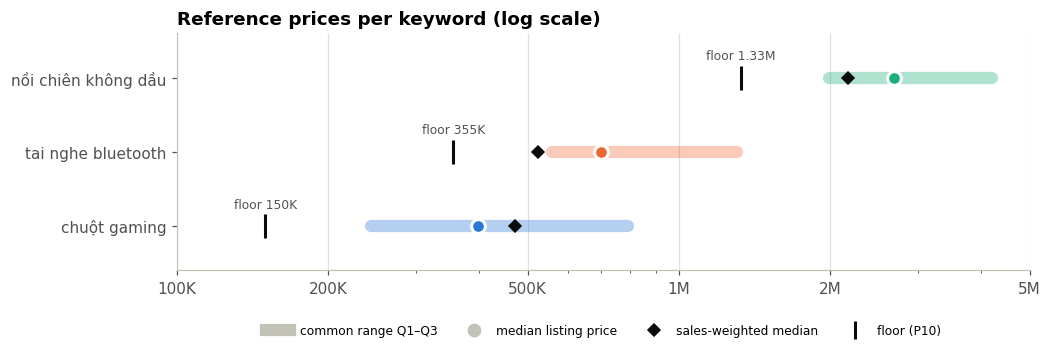

In [11]:
fig, ax = plt.subplots(figsize=(10, 2.8))
for y, (keyword, band) in enumerate(bands.iterrows()):
    color = COLORS[keyword]
    ax.plot([band["q1"], band["q3"]], [y, y], color=color, linewidth=8, solid_capstyle="round", alpha=0.35)
    ax.plot(band["floor"], y, "|", color=INK, markersize=16, markeredgewidth=2)
    ax.plot(band["median"], y, "o", color=color, markersize=9, markeredgecolor="white", markeredgewidth=2)
    ax.plot(band["sales_weighted_median"], y, "D", color=INK, markersize=6)
    ax.annotate(f"floor {vnd_short(band['floor'])}", (band["floor"], y), xytext=(0, 12),
                textcoords="offset points", ha="center", fontsize=8, color=INK2)
ax.set_xscale("log")
ax.set_xticks([100_000, 200_000, 500_000, 1_000_000, 2_000_000, 5_000_000])
ax.xaxis.set_major_formatter(vnd_short)
ax.xaxis.set_minor_formatter(FuncFormatter(lambda x, _: ""))
ax.set_yticks(range(len(bands)), bands.index)
ax.set_ylim(-0.6, len(bands) - 0.4)
ax.grid(axis="y", visible=False)
ax.set_title("Reference prices per keyword (log scale)")
ax.legend(handles=[
    plt.Line2D([], [], color=GRAY, linewidth=8, label="common range Q1–Q3"),
    plt.Line2D([], [], marker="o", linestyle="", color=GRAY, markersize=8, label="median listing price"),
    plt.Line2D([], [], marker="D", linestyle="", color=INK, markersize=6, label="sales-weighted median"),
    plt.Line2D([], [], marker="|", linestyle="", color=INK, markersize=12, markeredgewidth=2, label="floor (P10)"),
], loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=4, fontsize=8)
fig.savefig(FIGURES / "reference_prices.png", dpi=150, bbox_inches="tight")

| | floor (P10) | common range (Q1–Q3) | median listing | sales-weighted median |
|---|---|---|---|---|
| chuột gaming | 150K | 244K – 793K | 398K | **472K** |
| tai nghe bluetooth (true wireless) | 355K | 560K – 1.3M | 699K | **525K** |
| nồi chiên không dầu | 1.33M | 1.99M – 4.2M | 2.69M | **2.17M** |

Two different stories. For gaming mice, buyers pay **more** than the median listing (472K vs 398K): the best seller is a 472K Logitech G102. For wireless earbuds and air fryers, buyers pay **less** than the median listing (−25 % and −19 %): many listings are priced above what the market actually buys.

## 4. Which price segment sells — and how concentrated are sales?

Segments are cut at Q1 and Q3: **budget** (cheapest 25 %), **mid** (middle 50 %), **premium** (most expensive 25 %). If buyers did not care about price, each segment's share of units sold would equal its share of listings.

In [12]:
def segment_shares(group):
    band = price_band(group)
    segment = pd.cut(group["price"], [0, band["q1"], band["q3"], np.inf], labels=["budget", "mid", "premium"])
    table = group.groupby(segment, observed=False).agg(listings=("price", "size"), sold=("sold", "sum"))
    return (100 * table / table.sum()).rename(columns={"listings": "% of listings", "sold": "% of units sold"})

segments = pd.concat({keyword: segment_shares(group) for keyword, group in normal.groupby("keyword", sort=False)})
segments.round(1)

% of listings  % of units sold
                    price                                  
chuột gaming        budget            25.3              4.3
                    mid               49.3             57.4
                    premium           25.3             38.3
tai nghe bluetooth  budget            26.9             51.0
                    mid               47.8             13.3
                    premium           25.4             35.7
nồi chiên không dầu budget            25.1              3.2
                    mid               49.7             96.4
                    premium           25.1              0.4

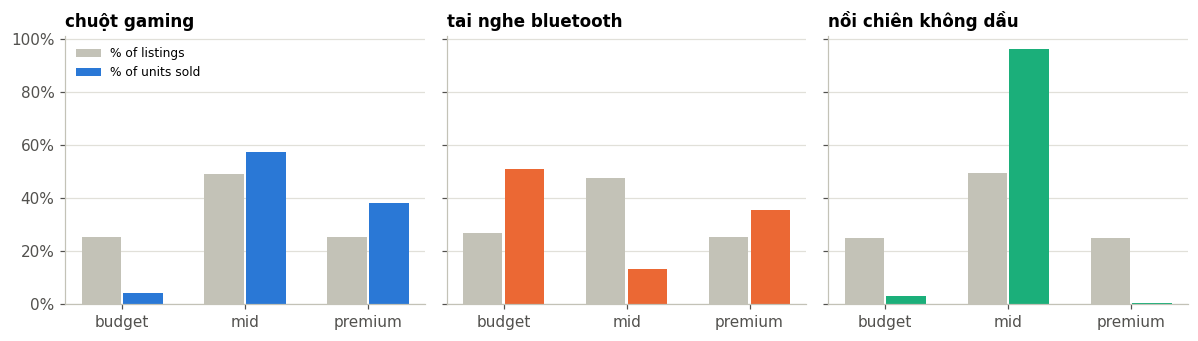

In [13]:
fig, axes = plt.subplots(1, len(KEYWORDS), figsize=(11, 3.2), sharey=True)
x = np.arange(3)
for ax, keyword in zip(axes, KEYWORDS):
    table = segments.loc[keyword]
    ax.bar(x - 0.17, table["% of listings"], width=0.32, color=GRAY, label="% of listings")
    ax.bar(x + 0.17, table["% of units sold"], width=0.32, color=COLORS[keyword], label="% of units sold")
    ax.set_xticks(x, table.index)
    ax.set_title(keyword, fontsize=11)
    ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
    ax.grid(axis="x", visible=False)
axes[0].legend(loc="upper left", fontsize=8)
plt.tight_layout()
fig.savefig(FIGURES / "segments.png", dpi=150, bbox_inches="tight")

If price did not matter, the coloured bars would match the gray ones. They do not:

- **Gaming mice:** the cheapest quarter of listings gets only **4 %** of units sold — the budget segment is crowded but does not sell.
- **Wireless earbuds:** the opposite — the budget segment (≤ 560K) takes **51 %** of units sold.
- **Air fryers:** **96 %** of units sold are in the mid range (2.0M – 4.2M).

Caution: in every category one or two best sellers weigh heavily (next table), so these shares describe a few products rather than whole segments.

In [14]:
def concentration(group):
    sold = group["sold"].sort_values(ascending=False)
    top10 = sold.head(max(1, round(len(sold) * 0.10))).sum() / sold.sum() * 100
    return pd.Series({"top 10% of listings: % of units sold": top10,
                      "listings with 0 sold %": (sold == 0).mean() * 100,
                      "best seller: % of units sold": sold.iloc[0] / sold.sum() * 100})

normal.groupby("keyword", sort=False).apply(concentration, include_groups=False).round(1)

,top 10% of listings: % of units sold,listings with 0 sold %,best seller: % of units sold
keyword,,,
chuột gaming,95.6,39.3,37.3
tai nghe bluetooth,90.9,37.3,44.5
nồi chiên không dầu,99.1,68.4,87.4


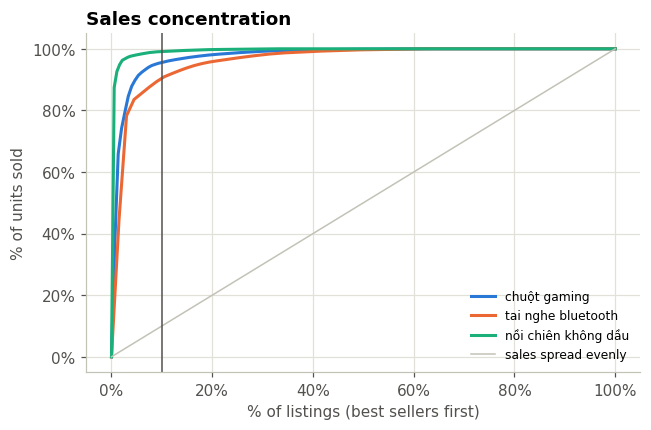

In [15]:
fig, ax = plt.subplots(figsize=(6.5, 4))
for keyword, group in normal.groupby("keyword", sort=False):
    sold = group["sold"].sort_values(ascending=False).to_numpy()
    listing_share = np.arange(len(sold) + 1) / len(sold) * 100           # starts at (0 %, 0 %)
    sold_share = np.concatenate([[0], sold.cumsum()]) / sold.sum() * 100
    ax.plot(listing_share, sold_share, color=COLORS[keyword], linewidth=2, label=keyword)
ax.plot([0, 100], [0, 100], color=GRAY, linewidth=1, label="sales spread evenly")
ax.axvline(10, color=INK2, linewidth=1)
ax.set_xlabel("% of listings (best sellers first)")
ax.set_ylabel("% of units sold")
ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.set_title("Sales concentration")
ax.legend(fontsize=8, loc="lower right")
fig.savefig(FIGURES / "concentration.png", dpi=150, bbox_inches="tight")

Sales are **extremely concentrated**: the top 10 % of listings take **91–99 %** of all units sold, and **37–68 %** of listings have never sold a single unit. In air fryers one product (Lock&Lock EJF296BLK, 2.17M) accounts for 87 % of the units sold.

For a new seller this means the number of listings overstates the competition: each market is decided by a handful of products.

## 5. What is related to sales?

Spearman correlation (rank-based) is used because sales and prices are heavily skewed and the relationships do not need to be linear.

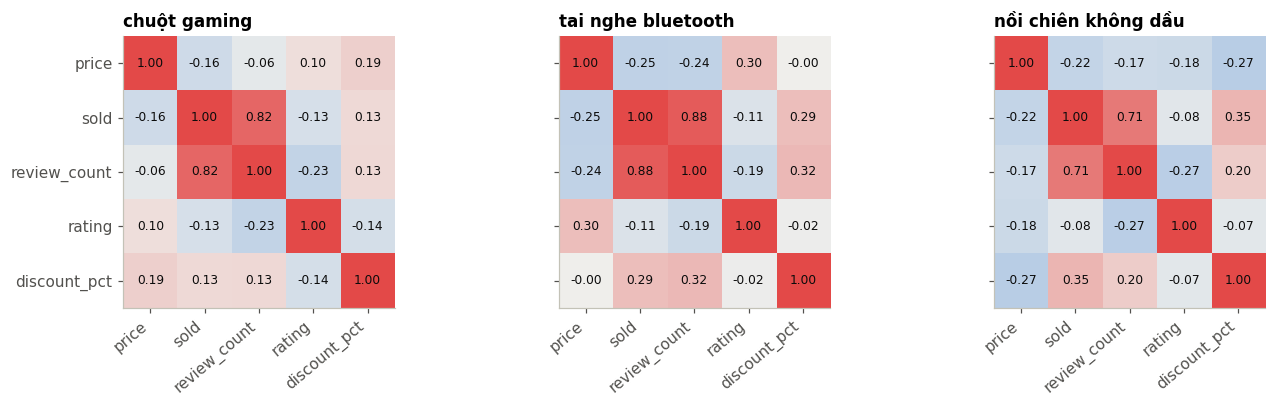

In [16]:
columns = ["price", "sold", "review_count", "rating", "discount_pct"]
corr = {keyword: group[columns].corr(method="spearman") for keyword, group in normal.groupby("keyword", sort=False)}

diverging = LinearSegmentedColormap.from_list("blue_gray_red", [BLUE, "#f0efec", "#e34948"])
fig, axes = plt.subplots(1, len(KEYWORDS), figsize=(13, 3.8))
for ax, keyword in zip(axes, KEYWORDS):
    matrix = corr[keyword]
    ax.imshow(matrix, cmap=diverging, vmin=-1, vmax=1)
    ax.set_xticks(range(len(columns)), columns, rotation=40, ha="right")
    ax.set_yticks(range(len(columns)), columns if ax is axes[0] else [])
    ax.grid(False)
    ax.set_title(keyword, fontsize=11)
    for i in range(len(columns)):
        for j in range(len(columns)):
            ax.text(j, i, f"{matrix.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8, color=INK)
plt.tight_layout()

In [17]:
pd.DataFrame({keyword: matrix["sold"].drop("sold") for keyword, matrix in corr.items()}).round(2)

,chuột gaming,tai nghe bluetooth,nồi chiên không dầu
price,-0.16,-0.25,-0.22
review_count,0.82,0.88,0.71
rating,-0.13,-0.11,-0.08
discount_pct,0.13,0.29,0.35


- **Reviews ↔ sold: ρ = 0.71 to 0.88.** Two independent fields agree, which is a good sign that the "sold" numbers are meaningful (a data-validation check, not a business insight).
- **Price ↔ sold: ρ = −0.16 to −0.25.** Cheaper products sell slightly more, but price explains little on its own.
- **Rating ↔ sold: ρ ≈ −0.1, no relationship.** Ratings are compressed: the median rated product has 5.0★ and 69 % of all products have no rating at all, so stars barely separate products. This is why the deal score ranks a Bayesian-adjusted rating instead of raw stars.
- **Discount ↔ sold: ρ = 0.13 to 0.35**, strongest for air fryers.

In [18]:
# Rating distribution of rated products: how much room is there to tell products apart?
normal.groupby("keyword", sort=False)["rating"].describe()[["count", "mean", "25%", "50%", "75%"]].round(2)

,count,mean,25%,50%,75%
keyword,,,,,
chuột gaming,58.0,4.56,4.50,5.0,5.0
tai nghe bluetooth,32.0,4.68,4.65,5.0,5.0
nồi chiên không dầu,28.0,4.74,4.78,5.0,5.0


In [19]:
# Discounted vs not discounted
normal.assign(discounted=normal["discount_pct"] > 0).groupby(["keyword", "discounted"]).agg(
    products=("price", "size"), median_price=("price", "median"), median_sold=("sold", "median")
).round(1)

products  median_price  median_sold
keyword             discounted                                     
chuột gaming        False            136      382000.0          1.0
                    True              14      799500.0          2.0
nồi chiên không dầu False            144     2942900.0          0.0
                    True              43     2190000.0          1.0
tai nghe bluetooth  False             55      699000.0          1.0
                    True              12      744000.0         12.5

Discounted products have higher median sales (earbuds: 12.5 vs 1 unit). This is a **correlation, not proof that discounts cause sales**: sellers may promote products that already sell, and only today's discount is visible — there is no price history to check whether the "original price" was ever charged.

## 6. Does the deal score pick sensible products?

`deal_score = 100 × (0.3 × cheap rank + 0.4 × sold rank + 0.3 × adjusted-rating rank)`, computed inside each category; the rating is adjusted with a Bayesian average so that 5★ from one review does not beat 4.8★ from a thousand.

In [20]:
top_deals = (normal.sort_values("deal_score", ascending=False).groupby("keyword", sort=False).head(3)
             .sort_values(["keyword", "deal_score"], ascending=[True, False])
             [["keyword", "name", "price", "sold", "rating", "review_count", "deal_score"]])
top_deals

,keyword,name,price,sold,rating,review_count,deal_score
128,chuột gaming,Chuột Dareu LM103- Màu đen - Hàng Chính hãng,80000,100,5.0,7,96.3
10,chuột gaming,Chuột LED RGB 3200 DPI Gaming Mouse A868 chống mỏi ...,185000,106,4.8,13,91.0
106,chuột gaming,Chuột máy tính chuyên phòng Game Newmen G7Plus_Hàng...,250000,204,4.8,37,89.0
450,nồi chiên không dầu,Nồi chiên không dầu Philips 6.2 lít NA130/00 - Hàn...,1350000,126,4.8,27,95.5
379,nồi chiên không dầu,"Nồi chiên không dầu thế hệ mới dung tích lớn, công ...",650000,14,5.0,1,95.0
421,nồi chiên không dầu,Nồi chiên không dầu thủy tinh Mishio MK373 - Dung t...,999000,16,5.0,1,94.6
174,tai nghe bluetooth,Tai Nghe Bluetooth Cao Cấp EQ2 5.3 Pin 7h Âm Thanh ...,359000,1143,4.7,190,94.6
216,tai nghe bluetooth,Tai nghe bluetooth nhét tai TWS ROCK EB710 - Hàng c...,325000,47,5.0,10,93.9
332,tai nghe bluetooth,Tai nghe Bluetooth True Wireless Redmi Buds 6 Play ...,328000,26,4.8,5,88.7


In [21]:
# Are the top deals cheaper than the median, and do they sell?
summary = []
for keyword, group in normal.groupby("keyword", sort=False):
    best = group.nlargest(10, "deal_score")
    summary.append({"keyword": keyword,
                     "median price, top 10 deals": best["price"].median(),
                     "median price, all": group["price"].median(),
                     "median sold, top 10 deals": best["sold"].median(),
                     "median sold, all": group["sold"].median()})
pd.DataFrame(summary).set_index("keyword").round(0).astype(int)

,"median price, top 10 deals","median price, all","median sold, top 10 deals","median sold, all"
keyword,,,,
chuột gaming,194500,398000,54,1
tai nghe bluetooth,445000,699000,26,1
nồi chiên không dầu,1287500,2690000,15,0


The top-10 deals cost about **half the median price** (195K vs 398K for mice, 445K vs 699K for earbuds, 1.29M vs 2.69M for air fryers) and they **do sell** (median 15–54 units, against 0–1 for all products). The score does what it promises — cheaper than usual *and* proven by buyers. It remains a heuristic: the weights 0.3 / 0.4 / 0.3 were chosen, not learned from purchase data.

## Conclusions

1. **A floor price can be estimated from listings alone:** gaming mouse ≈ 150K, true-wireless earbuds ≈ 355K, air fryer ≈ 1.33M (10th percentile of normal prices). A listing below that deserves a closer look.
2. **Listing prices are not paid prices.** The sales-weighted median differs from the listing median by −25 % to +19 %; for a seller it is the better benchmark.
3. **These markets are winner-take-most:** about 10 % of listings take more than 90 % of the units sold.
4. **Star ratings are a weak signal** (mostly 5★ or missing); the number of reviews is a much better proxy for popularity.
5. **Data-quality decisions mattered more than formulas:** analysing one category at a time, treating 0★ as missing and working on log prices changed the results more than any weight in the deal score.

**Limitations:** one snapshot, Tiki only, the first 200 results of each search, cumulative sold counts.

**Next step:** collect the same keywords every day to measure price changes over time and to check whether advertised discounts are real.